# Homework 4: Dimensionality reduction

This assignment has 3 parts. Each part is graded as listed in its heading.

## Homework 4.1 (32 points)

**Learning objectives:**

In this assignment, we will delve into linear dimensionality reduction. We will explore:

* Principal components analysis
* Related linear algebra

---
Load the same libraries that we used in previous modules:

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `pandas` as (`pd`)

Now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 1 (2 points)
*   Load the Olympic Decathalon dataset. This dataset includes the performance of 41 olympic athletes for the 10 events of the decathlon. There are 14 columns in total: the first is the athlete's name, the next ten columns correspond to the performance of each athlete for the 10 events of the decathlon (e.g. 100 meter dash, long jump, etc.). Columns 11 and 12 correspond to the athlete's rank and the points obtained. The last column corresponds to the sporting event (2004 Olympic Game or 2004 Decastar). These data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework4/decathalon.csv

*    To do this, use the pandas function `pd.read_csv` to create a a `pandas` DataFrame, which we will call `df`:

In [ ]:
# Your code here


Let's explore this object using some common `pandas` methods.

* Use the [`dataframe.head()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.head.html) method to show the first `n=10` rows of your dataframe `df`.

In [ ]:
# Your code here


---
### Part 2 (2 points)

You might immediately notice that the data can naturally be represented on wildly different scales. For example data for `1500m` is in the hundreds while `high jump` is in the single digits. This is generally bad for data analysis purposes, and we aren't generally intersted in the overall scale of things when we do dimensionality reduction, but the covariation of variables.

For that reason, we want to scale the data to be on the roughly on the same scale. A standard way to do this is to `z-score` the data for each feature (e.g. each event). Recall z-scoring from Module 1:

$z_{ij} = \frac{(x_{ij} - \mu_j)}{\sigma_j}$

where each $x_{ij}$ is a datapoint and $\mu_j$ and $\sigma_j$ are the mean and standard deviation, respectively, of the $j^{th}$ feature, i.e. $j=1$ corresponds to `100m`, etc.

* First, let's create a reduced dataframe, called `X` that removes some of the information from our dataset that we don't need, such as the athletes name, their rank, points, and which sporting event the data corresponds to. These correspond to the first, and last three columns of out dataframe. A dataframe has some handy functionality that we will exploit. Each dataframe has an attribute `.columns` which lists the column names of the dataframe. This can be indexed into (i.e., [1:2], etc.) to pull out only the column names we are intersted in. THEN, this list of column names can be used to index into our dataframe itself, to only take the columns we are interested in. Use `X = df[df.columns[1:-3]]` to generate a reduced dataframe `X` of the data we want.

* Use the [`mean`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.mean.html) and [`std`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.std.html) method for a dataframe (I.E. NOT np.mean and np.std that we have been using in `numpy`!) to z-score our data. Create a new scaled dataframe, `X_scaled`. Set the `ddof=0` option for `std`. The reason for doing this will become clear soon.

🚩 **Common mistake:** pandas `.std()` defaults to `ddof=1` while `np.std` defaults to `ddof=0`, so forgetting `ddof=0` gives z-scores that run without error but are slightly off and will not match `StandardScaler` later.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 3 (2 points)

Z-scoring data is such a common preprocessing step, that Scikit-learn has built in functionality for doing it.

* import [`StandardScaler`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html) from `sklearn.preprocessing`
* Create a `StandardScaler` instance using `StandardScaler()`.
* Apply the [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.StandardScaler.html#sklearn.preprocessing.StandardScaler.fit_transform) method to our unscaled data `X` and create a new variable `X_scaled_2`. `X_scaled_2` is returned as a numpy array; use the pandas method [`to_numpy`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.to_numpy.html) to convert `X_scaled` to a numpy array and use the [`.all()`](https://numpy.org/doc/stable/reference/generated/numpy.all.html) method to compare `X_scaled` and `X_scaled_2`. They should match.


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 4 (2 points)

* Use the [`dataframe.corr()`](https://pandas.pydata.org/docs/reference/api/pandas.DataFrame.corr.html) method to compute the correlation matrix of `X_scaled`.

* Plot it using `plt.imshow()`. Label each row and column with the appropriate name of each variable. The `.columns` attribute of our dataframe `X_scaled` will be helpful here.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 5 (2 points)

* From our correlation matrix, it looks like `Discus` and `Shot put` are positively correlated. Plot a scatter plot of the scaled values of these two features for all the datapoints to see this visually.

In [ ]:
# Your code here


---
### Part 6 (2 points)

* The first step in performing PCA is to compute the covariance matrix of our data. If our data matrix is the scaled matrix `X_scale` which is dimensions of $N$ datapoints by $P$ features, our covariance matrix is $S = X^TX$.

* To make things easier, create a numpy array called `X_scaled_np` using `.to_numpy`.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 7 (2 points)

* Next, we want to compute the eigenvectors and eigenvalues of our covariance matrix. Use the numpy method [`np.linalg.eig`](https://numpy.org/doc/stable/reference/generated/numpy.linalg.eig.html) to do this.

* Once we have our eigenvectors, we can compute our principal components by multiplying our data matrix with the eigenvectors. Do this, and then plot a scatter plot of the first two principal components. Additionally, use the `Points` column from our original dataframe to color the points. With two components we can see separation between higher and lower performance. This is **NOT** necessarily the case, PCA is unsupervised so it is not finding axes that relate to any outcome measure by design, just ones that explain the most variance across the features. This case happens to work really nicely!

🚩 **Common mistake:** `np.linalg.eig` returns eigenvectors as the *columns* of the output matrix (not rows), and the eigenvalues are not guaranteed to be sorted. Taking `vecs[0]` or assuming the first column is the largest-variance direction runs fine but gives the wrong components.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 8 (2 points)

For a given eigenvector, each element tells us how much each feature contributes to the associated principal component. We can examine these values to understand how PC1, etc. are being constructed.

* Plot the elements of the first eigenvector as points, setting the x axis to the feature names. (For getting the names of the features on the x-axis, `plt.xticks` and `.columns` will be helpful).

In [ ]:
# Your code here


<font color='red'>**SHORT ANSWER (4 points):** In words, describe which features have large values and which features have small values. How are the features with small and large values respectively similar and different? If the combination of features produces the first principal component, how might we describe the 'nature' of the first component? (Think -- if these features combine to produce it, what 'name' could we give this 'new' feature'?)</font>  

---
### Part 9 (2 points)

* Now that we implemented PCA ourselves, its time to take advantage of sklearn.

* Import [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA.transform) from `sklearn.decomposition`.

* Create an instance of `PCA()` called `pca`.

* Use [`fit_transform`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA.fit_transform) on the X_scaled data to perform PCA and project the data into the principal components. Woah!

* As above, plot a scatter plot of the first two principal components. It should look like our plot from above.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 10 (2 points)

* Our fit `pca` instance contains an attribute called `components_` which contains the 'loadings' of the data onto the principal components (i.e. the eigenvectors of the covariane matrix.) Plot a scatter plot of the entries of the first loading against the name of the feature, as we did above. It should look the same.

In [ ]:
# Your code here


---
### Part 11 (2 points)

* The eigenvalues tell us how variance from our original data is distributed across each principal component direction. Compute the sqrt of the eigenvalues from the eigenvalue decomposition we did by hand against the attribute of our `pca` instance called `singular_values_`, which is the singular values of our data matrix. Although we are not going to cover signular value decomposition, as a reminder from linear algebra, the eigenvalues are the singular values squared.

Notice that the order is not quite the same. This isn't important -- the two methods simply order things differently.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 12 (2 points)

The ratio of the cumulative sum of our eigenvalues to its total sum will tell us how much variance in our dataset our successive principal components represent. Plot this as a scatter plot two ways:

* Using our computed eigenvalues
* Using the `explained_variance_ratio_` attribute of our `pca` instance.

In [ ]:
# Your code here


<font color='red'>**SHORT ANSWER (4 points):** Given the distribution of variance we are seeing here, what does that tell you about how one should train for a decathalon? Should I train for each event seperately? What if instead I trained in such a way to build up a specific set of skills? Does there seem to be much benefit, according to the picture from PCA, of building up the skill along the last PC?</font>  

In [ ]:
# Your code here


## Homework 4.2 (32 points)

**Learning objectives:**

In this assignment, we will delve deeper into linear dimensionality reduction, exploring connections between dimensionality reduction and classification. We will explore:

* Dimensionality reduction using LDA, and its relationship to PCA

---
Load our standard libraries:

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `pandas` as (`pd`)

Now is also a good time to set the default font size to 16.

In [ ]:
# Your code here


---
### Part 1 (2 points)
For this assignment, we are going to analyze the somewhat famous ['wine analysis' dataset](https://scikit-learn.org/stable/modules/generated/sklearn.datasets.load_wine.html). These data are the result of a chemical analysis of wines grown in the same region in Italy but derived from three different cultivars. The analysis determined the quantities of 13 constituents (e.g. alcohol, malic acid, etc.) found in each of the three types of wines.

Load the dataset: these data are stored in a .csv (comma separated values) file at the following URL:

https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework4/wine.csv'

*  Use the pandas function `pd.read_csv` to create a a `pandas` DataFrame, called `df`.

* Use `.head()` to take a look at the different features of the dataset.

In [ ]:
# Your code here


---
### Part 2 (2 points)

Let's get organized a bit. We are going to use LDA to do dimensionality reduction on our wine data. This dataset has 13 attributes, 178 samples, and 3 classes, so things can get confusing fast. Let's create seperate arrays for each class to make our life easier.

* Create 3 numpy arrays, `X1`, `X2` and `X3`, one for each data of class.

* Create a numpy vector `y` with the class labels.

* Create a numpy matrix `X` of the data for ALL classes.

In [ ]:
# Your code here


---
### Part 3 (2 points)

With 13 dimensions in our dataset, we can't even visualize how the different classes cluster! Are they super tangled up? All spread out?

Let's say we didn't know anything about LDA yet, but we were super experts on PCA. Data got too many dimensions -- do PCA! That will solve the problem! Let's see...

* Compute the mean of the whole dataset (for all classes, i.e. `X`) and called it `m`.
* Compute the covariance matrix of `X` - `m` and call it `ST`.

<font color='red'>**NOTE: throughout this assignment, we will compute the covariance matrix of a data matrix `X` as C = $X^TX$ (or $XX^T$ when appropriate) without a normalization factor. This means that you need to compute it yourself using `np.dot` or `np.matmul`, without using `numpy.cov`. This isn't to punish you, but just because if your normalize these covariance matrices, you need to do so consistently across ALL of the analyses we do, and its just a pain if they are normalized - it's easier if they are not.** </font>  

* Compute the eigenvectors of `ST`.

* Project `X` - `m` down onto the first 2 PCs.

* Plot the data (with the mean removed) colored by class (class_0: `blue`, class_1: `red`, class_2: `green`) projected down onto the first 2 PCs. Add a legend so its clear which class is which.

Your plot should look like this. What a mess!

🚩 **Common mistake:** calling `np.mean(X)` without `axis=0` returns a single number for the whole matrix instead of one mean per feature, so `X - m` runs without error but does not actually center each feature.

In [ ]:
# Your code here


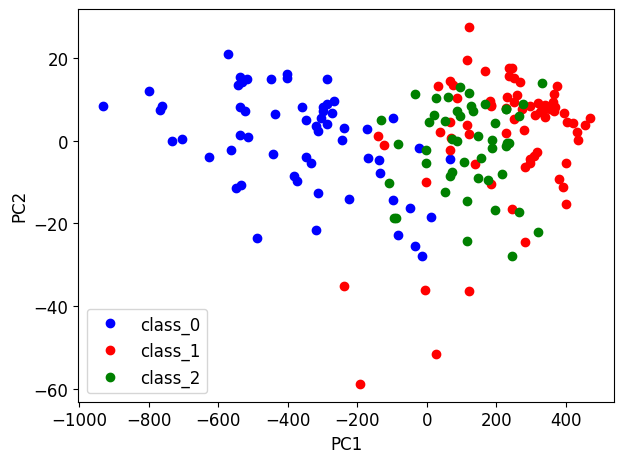

In [ ]:
# Your code here


---
### Part 4 (2 points)

Maybe using some information about which class each datapoint is in will help us? Let's try doing PCA on the _mean_ value of each class. Maybe, if the mean values are super spread out, and each data point is not too far from its classes' mean, maybe the eigenvalues of the class means will be a good set of axes to project the data on?

* Compute the mean of the data within each class.

* Compute the covariance matrix of the class means. In class, this was defined as $$S_B = \sum_k N_k (m_k - m)(m_k - m)^T$$

where $N_k$ is the number of data points in the $k^{th}$ class and $m$ is the mean over all datapoints.

* In class, I noted that because $S_B$ is comprised of a sum of $K$ matrices that are constructed as vector [outer products](https://en.wikipedia.org/wiki/Outer_product) and because $\frac{1}{N}\sum_k N_k m_k = m$, the [rank](https://en.wikipedia.org/wiki/Rank_(linear_algebra)) of $S_B$ should be $K-1$, i.e. 2 in our case. Verify this.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 5 (2 points)

Do PCA on the class mean covariance matrix.

* Compute the eigenvectors of `SB`.

* Project `X` - `m` down onto the first 2 PCs.

* Plot the data (with the mean removed) colored by class (class_0: `blue`, class_1: `red`, class_2: `green`) projected down onto the first 2 PCs. Add a legend so its clear which class is which.

Your plot should look like this.

In [ ]:
# Your code here


In [ ]:
# Your code here


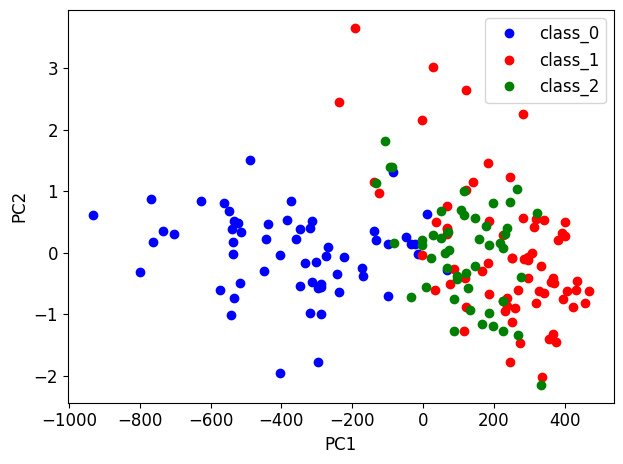

In [ ]:
# Your code here


---
### Part 6 (2 points)

OK, clearly using the covariance of all the data (without any class information) OR only using the mean information for each class isn't going to cut it. In class, we learned how LDA projects the data down to a lower dimension such that 1. the distance between class means is large and 2. the within classes covariance is small.

Recall from class that the projection $W$ that does this can be computed by solving $$J(W) = Tr(\frac{W^TS_BW}{W^TS_WW}).$$

The solution yeilds that $W$ will be the eigenvectors of $S_W^{-1}S_B$.

We already computed `SB`. Let's compute `SW`, the within class covariance.

* Compute the within class covariance matrix by computing the covariance of the data in each class and summing each covariance matrix. Recall that the data for each class should have its class mean removed. I.e., compute $$\sum_k (X_k - m_k)(X_k - m_k)^T$$

* In class, we derived the expression for $S_B$ by noting that it should be the remaining variance when the within class variance is subtracted from the total data variance. Validate this is true for the `SB` you calculated above.

🚩 **Common mistake:** the formula $(X_k - m_k)(X_k - m_k)^T$ assumes each column is a sample. If your `X_k` has samples as rows, as it does here, that product is $N_k \times N_k$ rather than $13 \times 13$, so check the shape of `SW` and transpose accordingly.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 7 (2 points)

Let's finally do LDA.

* Compute the eigenvectors of $S_W^{-1}S_B$.

* Project `X` - `m` down onto the first 2 PCs.

* Plot the data (with the mean removed) colored by class (class_0: `blue`, class_1: `red`, class_2: `green`) projected down onto the first 2 PCs. Add a legend so its clear which class is which.

Your plot should look like this.

In [ ]:
# Your code here


In [ ]:
# Your code here


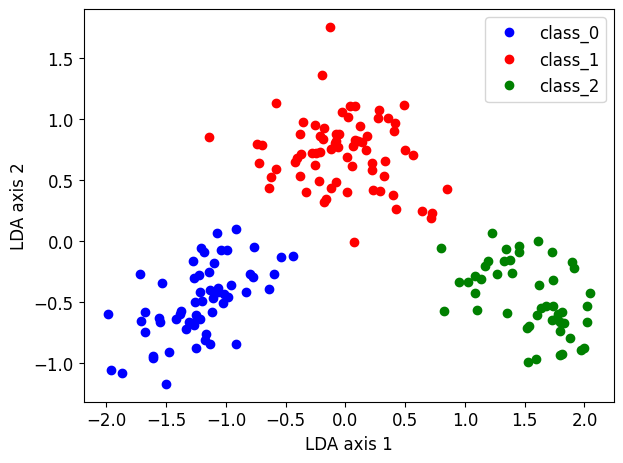

In [ ]:
# Your code here


---
### Part 8 (2 points)

In class, I noted how the $S_W^{-1}$ term in the expression $S_W^{-1}S_B$ acts something like a 'filter': it 'corrects' the covariance of the data based on the class means alone by the covariance within classes. In HW 4.1 we z-scored our data, which can also be thought of as a filter on the data: each feature is demeaned and normalized (but no feature-feature covariance is considered). So perhaps we need a better straw man to compare LDA against, rather than simple PCA.

* Scale the data `X` using `sklearn.preprocessing` `StandardScaler` then do PCA, as above. Plot your results.

Your plot should look like this. Looks better than regular PCA, but LDA is still looking better!

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


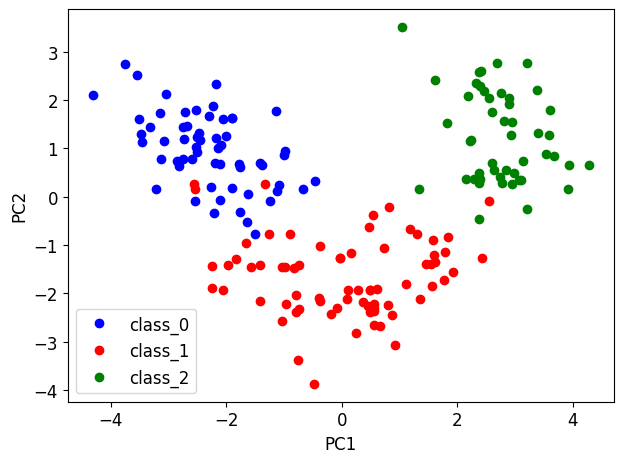

In [ ]:
# Your code here


---
### Part 9 (2 points)

In HW 4.1, we plotted the entries of the first few eigenvectors from PCA. The values of these entries told us which combinations of features gave rise to PC1, PC2, etc. We can do this again here!

* Plot the loadings of PC2 from PCA and for the class mean covariance matrix and for the covariance matrix of all the data. Use the feature labels for the x-axis labels so we can see the weigtht of each feature. What do you notice about these loadings?

* Do the same for the PC2 loadings for PCA on the scaled data and for the first eigenvector of LDA. What do you notice about these loadings that's different?

Your plots should look like this.


In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 10 (2 points)

Now that we've used LDA and projected our data down to a 2D space where we can see what the class clusters look like, let's do classification on our dataset and see how much better we are doing when compared to the best we could have done with PCA (scaled PCA).

Although discriminant vectors for each class can be derived directly from $W$ after LDA is performed to do dimensionality reduction (see [here](https://scikit-learn.org/stable/modules/lda_qda.html#lda)) the linear algebra gets a bit hairy. Instead, we will perform 'one against the others' classification, where we compute three discriminant vectors: one for each class against all the data of any other class.

In this way, 'one against the others' is much like a two-class classifcation problem, and because we've projected our data down to 2D, this is exactly the same situation we dealt with in HW3.1!

However, in HW3.1, we derived the slope and midpoint of the discriminant line by hand, and this was somewhat tedious. `sklearn`'s function `LinearDiscriminantAnalysis` provides these values for free, so let's use them.

<font color='red'>**NOTE: In order to get the values of the slope and midpoint, we will have to fit an LDA model again to our reduced dimensional data, but because the data has already been reduced to K-1 (i.e. 2) dimensions, no further reduction will be possible. This is just a bit of hack to exploit the functionality of `sklearn`.** </font>

* Project all the data `X` down using the first to eigenvectors from LDA. Call this new data matrix `LDs`.

* Use `LDs` as the data in `sklearn`'s `LinearDiscriminantAnalysis` which we used in HW3.1.

* For the class argument `y`, provide a boolean vector such that entries for `class_0` are `True` and all other entries are `False`. This is 'class_0 vs all other classes'.

* Fit the LDA using the method `.fit()`. See note above about this fitting (no further dimensional reduction is done!)

* The attribute `.intercept_` and `coef_` provide the slope and offset of the discriminant line. Recall that the equation for a hyperplane is many dimensions is $\sum_k a_k x_k + a_0$. For example, the equation of a line in 3D space would be $z = a_1x + a_2y + a_0$ much like the equation for a line in 2D is $y = a_1x + a_0%$. Our discrimnant in 2D occurs when $a_1x + a_2y + a_0 = 0$, which means that the equation of our line in 2D would be $y = -(a_0 + a_1x)/a_2$, where $a_1$ and $a_2$ are from `coef_` and $a_0$ is from `intercept_`. To plot this line, select a set of $x$'s that span the range of the first dimension of `LDs` and compute the value of $y$.

* Do the above procedure for 'one against the others' classification for each class.

* Plot our data colored by class (as above) and each discriminant line provided by `sklearn`.

Your plot should look like this:

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


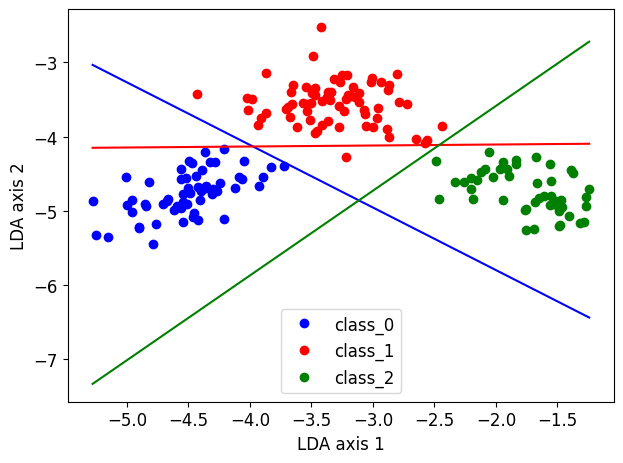

In [ ]:
# Your code here


---
### Part 11 (2 points)

As noted above, `LinearDiscriminantAnalysis` provides discriminant vectors for ALL classes directly from `W` (i.e. the 'one above each class' procedure we just did is not actually necessary, but it is more intuitive). To illustrate this potential, we will fit our LDA model again, but doing a 3 class classification. As above `LinearDiscriminantAnalysis` here will NOT do dimensionality reduction again (becuase we are already in the reduced space) but instead we will hack it to get the discriminant coefficients.

* Use `LDs` as the data in `sklearn`'s `LinearDiscriminantAnalysis` which we used in HW3.1.

* For the class argument `y`, use the class vector `y`. `LinearDiscriminantAnalysis` can handle vectors of strings.

* Fit the LDA using the method `.fit()`. See note above about this fitting (no further dimensional reduction is done!)

* The attribute `.intercept_` and `coef_` provide the slope and offset of the discriminant lines. This time, they will contain THREE sets of slopes and offsets, one for each discriminant line. Follow the procedure above to plot each line.

* Plot our data colored by class (as above) and each discriminant line provided by `sklearn`.

Your plot should look like this. NOTE that each line is doesn't look quite the same as when we did 'one vs. all other' class classification, becuase these lines are dervied by a different procedure (see [here](https://scikit-learn.org/stable/modules/lda_qda.html#lda)).

In [ ]:
# Your code here


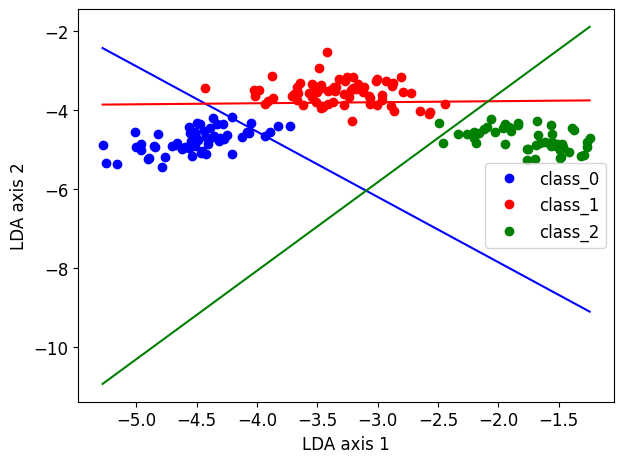

In [ ]:
# Your code here


---
### Part 12 (2 points)

As in HW3.1, we can project the data from each class along the discrinant vector using the method `decision_function`.

* Using `decision_function` project the data using our fit LDA from our 3-way classification (the one we just did above). Project the data along each discriminant and plot a histogram for each class, colored appropriately.

Your plot should look like this:

In [ ]:
# Your code here


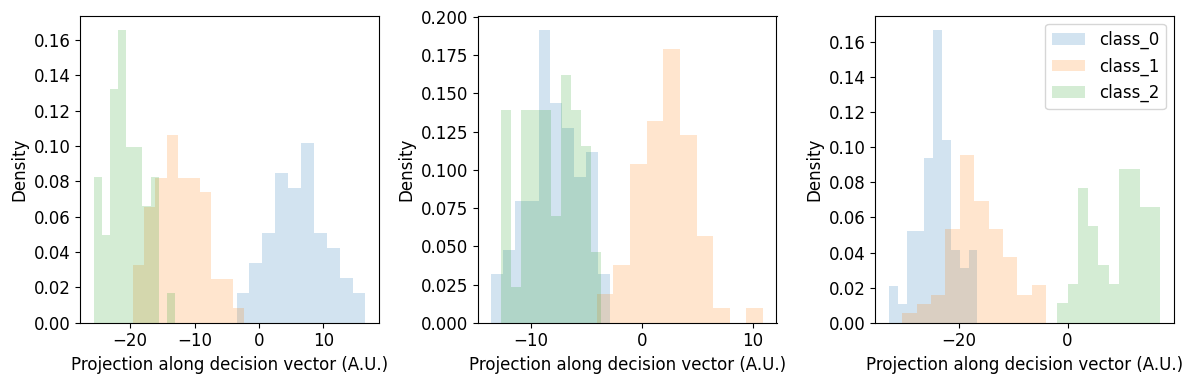

In [ ]:
# Your code here


---
### Part 13 (2 points)

* Use the [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html#sklearn.discriminant_analysis.LinearDiscriminantAnalysis.predict) method to compute the prediction accuracy of our 3-way classification.

In [ ]:
# Your code here


In [ ]:
# Your code here


---
### Part 14 (2 points)

Do a 3 class classification, as above, using `LinearDiscriminantAnalysis` on the data projected down onto the first two **scaled PCs!**

** Define `PCs_scaled` as your scaled data projected onto the first two eigenvectors from PCA on the scaled data.

* Use `PCs_scaled` as the data in `sklearn`'s `LinearDiscriminantAnalysis` which we used in HW3.1.

* For the class argument `y`, use the class vector `y`. `LinearDiscriminantAnalysis` can handle vectors of strings.

* Fit the LDA using the method `.fit()`. See note above about this fitting (no further dimensional reduction is done!)

* The attribute `.intercept_` and `coef_` provide the slope and offset of the discriminant lines. This time, they will contain THREE sets of slopes and offsets, one for each discriminant line. Follow the procedure above to plot each line.

* Plot our data colored by class (as above) and each discriminant line provided by `sklearn`.

Your plot should look like this.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


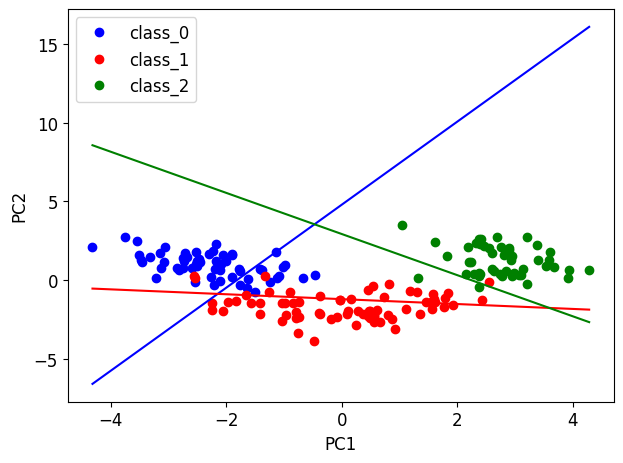

In [ ]:
# Your code here


---
### Part 15 (2 points)

* Using `decision_function` project the data using our fit LDA from our 3-way classification (the one we just did above). Project the data along each discriminant and plot a histogram for each class, colored appropriately.

Your plot should look like this:

In [ ]:
# Your code here


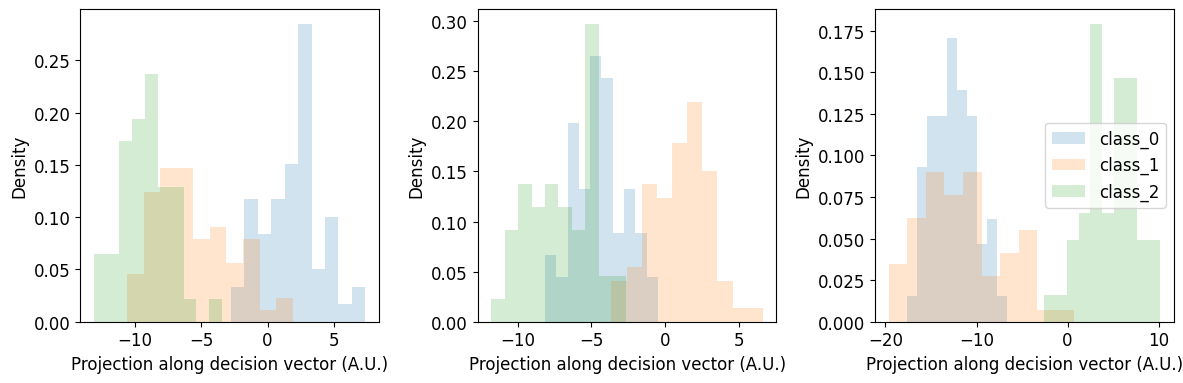

In [ ]:
# Your code here


---
### Part 16 (2 points)

* Use the [`predict()`](https://scikit-learn.org/stable/modules/generated/sklearn.discriminant_analysis.LinearDiscriminantAnalysis.html#sklearn.discriminant_analysis.LinearDiscriminantAnalysis.predict) method to compute the prediction accuracy of our 3-way classification.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


## Homework 4.3 (46 points)

**Learning objectives:**

In this assignment, we will continue to explore dimensionality reduction. We will:

* make connections between dimensionality reduction via principal components regression and other regression methods such as partial least squares and ridge regression.

* See how probabilistic approaches such as PPCA and factor analysis can be used for model selection.

---
Load our standard libraries, and set our standard font size:

*   `numpy` (as `np`)
*   `matplotlib.pyplot` (as `plt`)
*   `pandas` as (`pd`)


In [ ]:
# Your code here


### Part 1 (4 points)

We are going to work through a toy dataset to see how partial least squares can improve regression results when compared to principal components regression. This toy dataset was originally considered [here](https://scikit-learn.org/stable/auto_examples/cross_decomposition/plot_pcr_vs_pls.html#sphx-glr-auto-examples-cross-decomposition-plot-pcr-vs-pls-py). All code cells will be shown here, but pay attention to what's going on, so you can perform a similar analysis below!

First, let's generate a synthetic 2 dimensional dataset. This will help us understand what principal components regression and partial least squares are doing.

In [ ]:
rng = np.random.RandomState(0) #set the random seed
n_samples = 500 #how many samples of data to use
cov = [[3, 3], [3, 4]] #construct the covariance matrix, which will determine how feature 1 and 2 covary
X = rng.multivariate_normal(mean=[0, 0], cov=cov, size=n_samples) #create the 2 dimensional data

Do PCA on this fake data.

In [ ]:
from sklearn.decomposition import PCA
pca = PCA(n_components=2).fit(X)

And then plot it. It should be clear that PC1 is larger then PC2.

In [ ]:
plt.scatter(X[:, 0], X[:, 1], alpha=0.3, label="data")

for i, (comp, var) in enumerate(zip(pca.components_, pca.explained_variance_)):
    comp = comp * var  # scale component by its variance explanation power
    plt.plot([0, comp[0]], [0, comp[1]],
        label=f"Component {i+1}",
        linewidth=5, color=f"C{i + 2}")

plt.gca().set(
    aspect="equal",
    title="2-dimensional dataset with principal components",
    xlabel="first feature",
    ylabel="second feature")

plt.legend();

Now, let's create a variable that we might want to predict, `y` as a function of **PC2**. This means that the smaller PC2 is the most predictive dimension of `y`.

In [ ]:
y = X.dot(pca.components_[1]) + rng.normal(size=n_samples) / 2

Plotting a scatter plot of this should make it the most clear: PC1 is not very correlated with `y` and PC2 is very correlated with it!

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))

axes[0].scatter(X.dot(pca.components_[0]), y, alpha=0.3)
axes[0].set(xlabel="Projected data onto first PCA component", ylabel="y")
axes[1].scatter(X.dot(pca.components_[1]), y, alpha=0.3)
axes[1].set(xlabel="Projected data onto second PCA component", ylabel="y")
plt.tight_layout();

Now let's use `sklearn` to fit a [principal components regression](https://en.wikipedia.org/wiki/Principal_component_regression) (PCR) model and a [partial least squares](https://en.wikipedia.org/wiki/Partial_least_squares_regression) (PLS) model to these data.

In [ ]:
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import StandardScaler

[`make_pipeline`](https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.make_pipeline.html) is a handy method for 'stacking' together multiple processing steps into a single function, as we will need to do for PCR. Recall that PCR is two steps:

- Do PCA
- Do regression using the PCs.

First divide the data into a training and testing set using skelearn's method [`train_test_split`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.train_test_split.html).

In [ ]:
from sklearn.model_selection import train_test_split

In [ ]:
rng = np.random.RandomState(2)
X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=rng)

Let's use `make_pipline` to construct our PCR model, and then fit it. Recall from lecture that PCA simply seeks to find directions within the covariance of our `X` data that lead to the maximum amount of variance. In other words it seeks to maximize an objection function of the form: $$ J(w) = \textrm{Var}(Xw).$$ So it will find PC1!

In [ ]:
pcr = make_pipeline(StandardScaler(), PCA(n_components=1), LinearRegression())
pcr.fit(X_train, y_train)

Because we used `make_pipeline` to fit our PCR model, the PCA 'part' of it is 'tucked within' our `pcr` object. To 'pull out' the PCA only part, we can use the attribute `named_steps`.

In [ ]:
pca = pcr.named_steps["pca"]

Now, let's fit the PLS model with 1 component. Recall from lecture that PLS is doing something different than PCA! It seeks to find large variance directions in `X` that ALSO correlate with `y`. In other words it seeks to maximize an objection function of the form: $$ J(w) = \textrm{Corr}^2(y, Xw) \textrm{Var}(Xw).$$ It will balance the $w$ that it finds to be sure that $Xw$ is correlated with $y$ (i.e. so it is predictive of $y$), but also that the variance of $Xw$ is large (much like a PC)!


[`PLSRegression`](https://scikit-learn.org/stable/modules/generated/sklearn.cross_decomposition.PLSRegression.html) is an easy to use sklearn method for fitting PLS models.

In [ ]:
from sklearn.cross_decomposition import PLSRegression

In [ ]:
pls = PLSRegression(n_components=1)
pls.fit(X_train, y_train);

Both `pca` (the part we pulled out of `pcr`) and `pls` have `transform()` methods associated with them, for projecting the original data into the lower-dimensional space. `pcr` (the object we created that does both PCA and linear regression) has a `predict` method associated with it (its just the `predict` method from the `linearregression` part of our pipeline). `pls` also has a `predict` method associated with it. Both methods compute the approximation to `y` based on their respective projection of the data.

* Let's plot a scatterplot for each method. First we will scatter the data projected down to the lower dimensional space against `y`. Second we will scatter the data projected down to the lower dimensional space against each model's prediction of `y`.

From the PCR/PCA plot, we can see that PCR finds PC1, which isn't very correlated with `y`, which we already knew. And as a result, the `pcr` prediction of `y` is pretty much zero everywhere.

From the PLS plot, we can see that PLS finds an axis that is correleated with `y`, and as a result, the `pls` prediction of `y` is pretty good!

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(10, 3))
axes[0].scatter(pca.transform(X_test), y_test, alpha=0.3, label="data")
axes[0].scatter(pca.transform(X_test), pcr.predict(X_test), alpha=0.3, label="predictions")
axes[0].set(xlabel="Projected data onto first PCA component", ylabel="y", title="PCR / PCA")
axes[0].legend()

axes[1].scatter(pls.transform(X_test), y_test, alpha=0.3, label="data")
axes[1].scatter(pls.transform(X_test), pls.predict(X_test), alpha=0.3, label="predictions")
axes[1].set(xlabel="Projected data onto first PLS component", ylabel="y", title="PLS")
axes[1].legend()
plt.tight_layout();

Finally, let's use the `score` method ([PLS](https://scikit-learn.org/stable/modules/generated/sklearn.cross_decomposition.PLSRegression.html#sklearn.cross_decomposition.PLSRegression.score) and [linear regression](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.LinearRegression.html)) to predict the model accuracy. Score is the coefficient of determination $R^2$ (i.e. 1 - normalized error).

In [ ]:
print(f"PCR r-squared {pcr.score(X_test, y_test):.3f}")
print(f"PLS r-squared {pls.score(X_test, y_test):.3f}")

---
### Part 2 (4 points)

Now that we've seen PLS in action against PCR, let's do the same analysis on our decathalon dataset.

First, let's more or less redo some steps from HW4.1.

*   Load the Olympic Decathalon dataset at the following URL: https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework4/decathalon.csv. To do this, use the pandas function `pd.read_csv` to create a a `pandas` DataFrame, which we will call `df`.

* Create a reduced dataframe, called `X` that removes some of the information from our dataset that we don't need, such as the athletes name, their rank, points, and which sporting event the data corresponds to. These correspond to the first, and last three columns of out dataframe. A dataframe has some handy functionality that we will exploit. Each dataframe has an attribute `.columns` which lists the column names of the dataframe. This can be indexed into (i.e., [1:2], etc.) to pull out only the column names we are intersted in. THEN, this list of column names can be used to index into our dataframe itself, to only take the columns we are interested in. Use `X = df[df.columns[1:-3]]` to generate a reduced dataframe `X` of the data we want.

**STEPS WITH CODE INCLUDED**

* Use `y = df[df.columns[-2:-1]]` to create a reduced dataframe of the points each athlete was awarded. We want to see if we can make a good prediction of this based on a projection of the data in `X` onto a reduced space of features.

* Use `features = X.columns` to make a list of the names of the features, for easy plotting.

* Scale the data in `X` using `sklearn`'s `StandardScaler()`.

* Divide the data into train and test sets using `train_test_split`. Set the optional arguments to `random_state=np.random.RandomState(2)` and `test_size=0.5`)

**STEPS WITH NO CODE INCLUDED**

* Use `make_pipeline` to create a pca analysis that includes a `standard_scaler()` step and a `pca` step.

* Fit your `pca` pipeline to your training data.

* Plot a scatter plot of the PC1 projection of your testing data against your `y` testing data. As we saw in HW4.1, PC1 is pretty correlated with `y`! But is it the *most* correlated linear projection of `X`?

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


### Part 3 (4 points)

Perform principal components regression and partial least squares on the decathalon dataset, much like we did above for the toy dataset.

* Perform both analysis to find a 1-dimensional projection of the data that best predicts $y$.

* To perform PCR, create a `pipeline` with the following components: a starndard scaler, PCA and linear regression. Fit the PCR model to the training data. Used `named_steps`, as we did above to pull out the components of the pipeline that we need to do plotting, etc.

* Plot a scatterplot for each method, as we did above. First we will scatter the data projected down to the lower dimensional space against `y`. Second we will scatter the data projected down to the lower dimensional space against each model's prediction of `y`.

* Compute the $R^2$ value for both models on test data, using the `score()` method, as we did above.

🚩 **Common mistake:** fitting the scaler or PCA on all the data before splitting leaks information from the test set into training. Put the scaler inside the pipeline and fit the pipeline only on the training set, so the test set is only ever transformed.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


### Part 4 (2 points)

Both PCR and PLS have found a 1-dimensional projection of the features in our data. In HW 4.1 we examined the loadings of this projection to understand what 'new feature' PC1 was representing. Let's do the same here for both methods.

* Plot the entries of PCR and PLS for the first dimension, setting the x axis to the feature names. (For getting the names of the features on the x-axis, `plt.xticks` and `.columns` will be helpful).

* For PLS, the attribute `.coef_` provides the projection vector.

* For PCR, our pipeline contains **TWO** components that collectively determine the projection vector: the `components_` attributue of the `pca` part determines the projection down to the lower dimension space and the `.coef_` attribute of the `linearregression` part determines how the data projected onto PC1 are scaled to predict `y`. In other words, the total projection vector of PCR is `linearregression.coef_` times `pca.components_`. Use `named_steps` to pull these out to plot the projection vector of PCR.

In [ ]:
# Your code here


<font color='red'>**SHORT ANSWER (4 points):** Name 1 feature that is similar between PCR and PLS and 1 feature that is different. What does this mean about what PLS is doing above and beyond PCA?</font>  

### Part 5 (4 points)

So far, we have examined the connection between PLS and PCA. Ridge regression (from module 2!) can also be connected to PCA/PCR in a way that is illuminating. We will examine that connection here.

PCR essentially 'zeros out' all discarded PCs and predicts `y` from the kept PCs. Ridge regression can be cast as a weighted sum of all the PCs to predict `y`, with smaller PCs being used less (but not discarded entirely). To see this we need to do some linear algebra, and recall the singular value decomposition of a matrix.

First, let's be careful with our dimensions. $X$, our data matrix, is a $N \times D$ matrix, where $N$ is the number of samples, and $D$ is the number of features.

Recall from the definition of the [singular value decompostion](https://en.wikipedia.org/wiki/Singular_value_decomposition) that any matrix can be written as

$$ X = U S V^T$$

where $U$ is a $N \times N$ [unitary, i.e. orthogonal in the case of a real values matrix](https://en.wikipedia.org/wiki/Orthogonal_matrix) matrix, $S$ is a $N \times D$ matrix with the singular values along its diagonal, and $V^T$ is a $D \times D$ unitary matrix.

If I compute the $D \times D$ covariance matrix of our data, $X^TX$, and subsititue our defintion of $X$ above, we can see that the singular value decomposition is related to the eigenvalue decomposition in the following way:

$$ X^T X = V S U^TU S V^T = VS^2V^T.$$

(Note that $U^TU = I$). Here we can see that $S^2$ are the eigenvalues and $V$ are the eigenvectors of the covariance matrix.

To make this more explicit, if I start with the singular value decomposition of $X$, $ X = U S V^T$, and multiply it on the right by $V$, I get $XV = USV^TV = US$. Recall that $V$ is $D \times D$, $X$ is $N \times D$, $U$ is $N \times N$ and $S$ is $N \times D$ and diagonal. $XV = US$ means that if I project my data onto the eigenvectors $V$ (ie compute the principal components) this should be equal to the rows of $U$ scaled by the corresponding singular value in $S$.

We are going to confirm this.

**STEPS WITH CODE INCLUDED**

* First, we need to remove the mean from our data. (This just makes subsequent analysis easier.)

**STEPS WITH NO CODE INCLUDED**

* Use `np.linalg.eig` to compute the eigenvalues and eigenvectors of $X^TX$ (of your demeaned data).

* Use `np.linalg.svd` to compute the singular values and the left singular vectors ($U$) of $X$ (demeaned).

* Project $X$ onto the first eigenvector to compute PC1. Multiply the first column of $U$ by the first singular value of $X$.

* Plot both to show they are the same thing (one may be the negative of the other, but they should be identical otherwise).

Your plot should look like this:

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


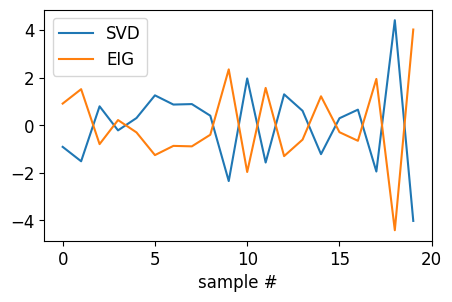

In [ ]:
# Your code here


### Part 5 (6 points)

In class, I derived an expression for the ridge solution that 'filters' $y$ based on the eigenvalues of the covariance matrix of $X$. I will illustrate that more fully here:

Recall that the ridge regression objective is $$J(w) = 1/2 ||y - X \beta||^2 + \lambda/2 ||\beta||^2,$$ where the ridge regression solution is

$$ \beta = (X^TX + \lambda I)^{-1}X^Ty$$

where $\beta$ is $D \times 1$. Recall that ridge regression is trying to find $y$ as linear combinations of $X$, $ y \approx X \beta$. If we plug $\beta$ in here, and plug in our singular value decompostion of $X$, $ X = U S V^T$, we get

$$ y \approx X \beta = X(X^TX + \lambda I)^{-1}X^Ty$$

$$ y \approx X \beta = U S V^T(VS^TU^TUSV^T + \lambda I)^{-1}V S^T U^Ty$$

(Note that $X^T = VSU^T$)

$$ y \approx X \beta = U S V^T(VS^TSV^T + \lambda I)^{-1}V S^T U^Ty$$

(Note that $U^TU = I$)

$$ y \approx X \beta = U S V^T(VS^TSV^T + \lambda VV^T)^{-1}V S^T U^TY$$

(Note that $I = VV^T = I$)

$$ y \approx X \beta = U S V^T(V(S^TS + \lambda)V^T)^{-1}V S^T U^Ty$$

(I pulled $V$ out to the left and $V^T$ out to the right).

(Next, note that $(ABC)^{-1} = C^{-1}B^{-1}A^{-1}$

$$ Y \approx X \beta = U S V^T((V^T)^{-1}(S^TS + \lambda)^{-1}V^{-1}V S^T U^Ty$$

(Note that $V^T(V^T)^{-1} = I$ and $V^{-1}V = I$)

$$ y \approx X \beta = U S (S^TS + \lambda)^{-1} S^T U^Ty$$

$$ y \approx X \beta = U S (S^TS + \lambda I)^{-1}S^T U^Ty$$

That was a long calculation! There is one more important point to mention: because $S$ is a $N \times D$ diagonal matrix, and generally $N > D$, all $D+1$ rows of $S$ will be all zeros! Which means that $U S$ will scale the first $D$ columns of $U$ by the respective element of $S$ and the $D+1$ columns of $U$ will essentially be zeroed out.

Because of the special stucture of $S$, its actually easier to think of the above expression in two parts:

- $U \frac{S^2}{S^2 + \lambda I}$ which will be equal to the first $D$ columns of $U$ each scaled by $\frac{s_d^2}{s_d^2 + \lambda I}$. Recall that $S^2$ will be the eigenvalues of $X^TX$, and so the scaling factor is the eigenvalues divided by the eigenvalues plus the regularization coefficient $\lambda$.

- $U^Ty$ which is the $N \times N$ matrix $U^T$ times the $N \times 1$ vector $y$. Recall from above that if each column of $U$ was proportional to an eigenvector of $X^TX$, then $U^T$ dotted with $y$ is the covariance of each of those columns with $y$, i.e. proportional to how much each eigenvector of the covariance of $X$ aligns with $y$! But again, because of the special structure of $S$, only the first $D$ columns (which correspond to the $D$ eigenvectors of $X^TX$ will be kept!)

So, in total this means the ridge solution $X \beta$ is a sum of $D$ $N$-dimensional vectors, where each vector is the product of $U_d \frac{s_d^2}{s_d^2 + \lambda} * (U_d \cdot y)$. $\frac{s_d^2}{s_d^2 + \lambda}$ and $(U_d \cdot y)$ are both scalars, and $U_d$ is proportional to the d-th principal component of $X$.

What do these two scalars do? Well if $U_d \cdot y$ is large, i.e. the d-th principal component of $X$ is correlated with $y$, that principal component will contribute strongly to the ridge solution (because this scalar will be big!). If $\frac{s_d^2}{s_d^2 + \lambda}$ is large, i.e. $\lambda$ is small (weak regularization) or a specific eigenvalue is very large, then again that principal component will contribute strongly to the ridge solution.

For example, we can compute $\frac{s_d^2}{s_d^2 + \lambda}$, for $\lambda = 10^{1}$ (i.e. a reasonably strong regularized ridge regression), using our singular values from above.

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(5, 3))
axes.plot(range(1, D+1), S**2 / (S**2 + 1e1), "x-");
axes.set(xlabel=r'$d_i$', xlim=[0, D+1], ylim=[0, 1]);

This essentially determines how 'much' of each PC will be 'available' for predicting $y$. (In PCR, for this plot all values below our PCA cutoff will be zero, all values above will be 1), such as the plot below.

In [ ]:
fig, axes = plt.subplots(1, 1, figsize=(5, 3))
axes.plot(range(1, D+1), S**2 / (S**2 + 1e1), "x-");
axes.plot(range(1, D+1), np.hstack([np.ones(1), np.zeros(D-1)]), "x-");
axes.set(xlabel=r'$d_i$', xlim=[0, D+1], ylim=[-0.1, 1.1]);
axes.legend(['Ridge', 'PCR'], fontsize=12);

So, what this is all telling us is that PCR and ridge are actually quite similar, in that they scale different eigenvectors of the covariance of our $X$ data to predict $y$, although they scale them in quite different ways.

That was alot. Let's do some analysis to make this more concrete.

<font color='red'>**(6 points):** You get all 6 points if you type the following statement here: "I read the above derivation" :) </font>  

### Part 6 (2 points)

The term from above $\sum_d^D \frac{s_d^2}{s_d^2 + \lambda}$ is referred to as the number of "degrees of freedom" of the ridge solution. It is effectively a measure of how many "dimensions" you are using, in a weighted way. In order to accurately compare our ridge solution to PCR, in which we used 1 principal component to do regression, we need to set our ridge penalty $\lambda$ appropriately so that our degress of freedom equals 1.

* Scan over values of lambda from $10^{-3}$ to $10^{4}$ using `10.**np.linspace(-3,4,num=20)` and compute the degrees of freedom of the ridge regression solution based on the covariance of our training data. (Note that we computed the singular values above!)

* Plot the degrees of freedom vs. $log_{10}(\lambda)$. Your plot should look like this:

* Not a suprise -- the degrees of freedom should range from $D=10$ to 0.

In [ ]:
# Your code here


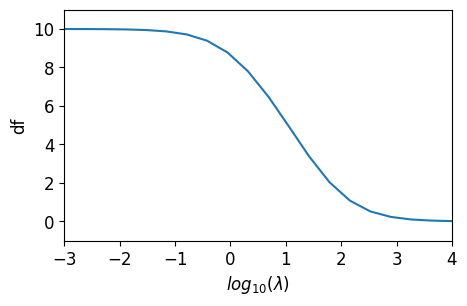

In [ ]:
# Your code here


### Part 7 (2 points)

To find the value of $\lambda$ such that the degrees of freedom is 1, we need to find when $df = 1$, or when $df - 1 = 0$, i.e the root of that function. We will use the `scipy.optimize` function [`root`](https://docs.scipy.org/doc/scipy/reference/generated/scipy.optimize.root.html) to do this.

* Do `from scipy.optimize import root`

* Define a function `DF(lam, S, df)` that takes in a value of $\lambda$ (`lam`), the singular values of $X$ (`S`) and the target degrees of freeom (`df`) and computes $\sum_d^D \frac{s_d^2}{s_d^2 + lam} - df$.

* Do `res = root(DF, 1e-1, args=(S, 1.0))` to find the root of your function when `df=1.0`. `res.l` will be the value of $\lambda$ at the root.

* Print the value of $\lambda$. It should match what is below.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


### Part 8 (2 points)

We are ready to fit our ridge regression with one degree of freedom!

* Use the `sklearn` class [`Ridge`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html). Remeber we used this in module 2! Do `from sklearn.linear_model import Ridge`.

* Demean your `y` training and testing data, like we did above for `X`.

* Do `ridge = Ridge(alpha=lam)` to create a ridge object with a regularization term `lam`.

* Use the [`fit`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge.fit) method of ridge to fit the model to your training data.

* Use the [`score`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge.score) method to show the $R^2$ on the testing data.

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


### Part 9 (4 points)

Recall from part 5 that we wanted to compare the weighted singular values of our $X$ matrix to the ridge solution. But, we didn't know how to weight them, because we didn't know which $\lambda$ we were going to use for regularization. Now we do!

* Compute $U_d \frac{s_d^2}{s_d^2 + \lambda}$ for the first $D=10$ singular vectors of $X$, i.e. the first $D$ columsn of $U$. Use the $\lambda$ we computed above to get the degress of freedom of our ridge solution to equal 1. You should have $D=10$ $N$-dimensional vectors.

* Compute the dot product between the demeaned values of your training data $y$ and the first $D$ singular vectors of $X$, i.e. the first $D$ columns of $U$. You have have $D$ scalar values.

* Plot the absolute value of $U_d \cdot y$ (for demeaned y training data). It should look like the plot below. This tells you how much each PC of $X$ covaries with $y$ in the training data. It's reasonable that there's a large value of PC1 (we'd hope so!) but the fact that this DOES NOT drop off monotonically suggests that large PCs aren't always the most predictive of $y$!

* Compute the product of $U_d \frac{s_d^2}{s_d^2 + \lambda} * U_d \cdot y$ for all $D$. This should give you $D$, $N$-dimensional vectors.

* Sum these vectors across $D$. (You should now have one $N$ dimensional vector.) Show this is equal to the prediction provided from the ridge solution of the training data, i.e. what your ridge solution returns when you use the [`predict`](https://scikit-learn.org/stable/modules/generated/sklearn.linear_model.Ridge.html#sklearn.linear_model.Ridge.predict) method of your ridge solution on you demeaned X training data.

* Plot $U_d \frac{s_d^2}{s_d^2 + \lambda} * U_d \cdot y$ for the first PC (i.e. the first column of $U$) and the last PC. You should plot 2, $N$-dimensional vectors.

* Plot the sum of $U_d \frac{s_d^2}{s_d^2 + \lambda} * U_d \cdot y$ across all $D=10$ PCs and the ridge solution. They should look the same. You should plot 2, $N$-dimensional vectors.

Your plots should look like this.

In [ ]:
# Your code here


In [ ]:
# Your code here


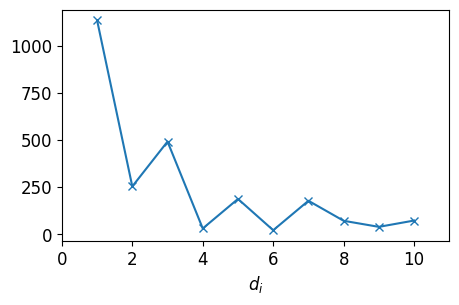

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


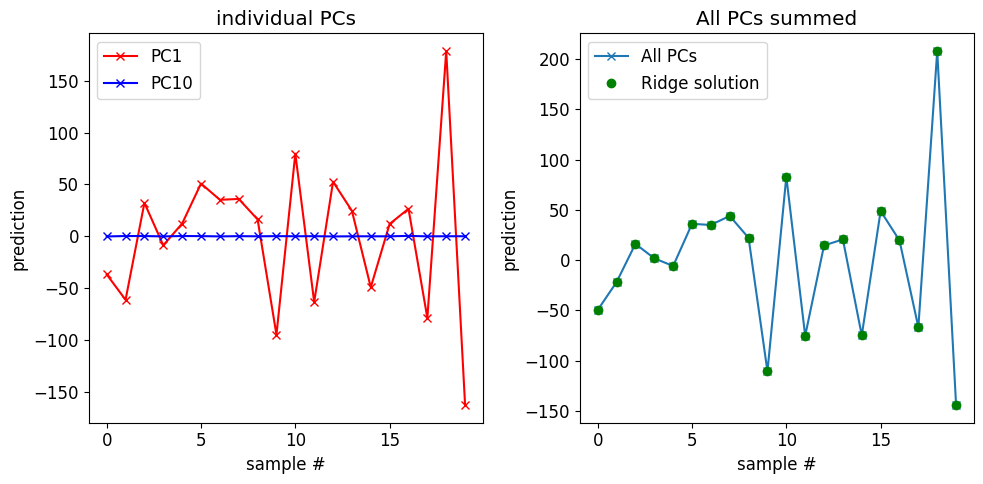

In [ ]:
# Your code here


Whew! That was intense! The punchline of that analysis was that we can think of ridge regression much like we think of PCR: taking a weighted combination of PCs to predict $y$, except that here we don't just pick 1 or 2 PCs, but pick them all, and weight them depending on how we choose $\lambda$.

### Part 10 (4 points)

Let's bring this all together now. Write a `for` loop, to loop over all dimensions (or degrees of freedom, in the case of ridge regression) from 1 to $D=10$ and fit all three models (PCR, PLS, ridge) on our training data and then compute $R^2$ on our testing data. (All of the components to do this you have already coded up, above, so just gather them and put them in a for loop).

* Plot the $R^2$ as a function of $d$ or degrees of freedom. Your plot should look like this:

In [ ]:
# Your code here


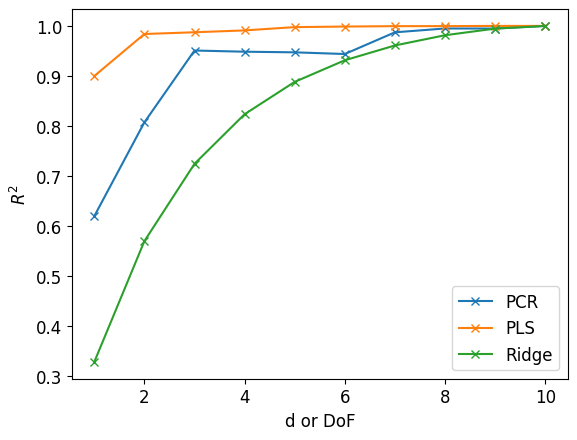

In [ ]:
# Your code here


### Part 11 (4 points)

Shifting gears, let's examine a dataset with PCA and factor analysis. Probabilistic PCA and FA are both great models because they are defined with an explicit log likelihood function which allows us to do model selection with cross-validation. (Standard PCA simply seeks projections that maximize variance -- it's not clear (although it is possible) how to formulate standard PCA for cross-validation). For this reason, and many others, moving into a probabilitic language is powerful!

We will use sklearn's implementation of [`PCA`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.PCA.html#sklearn.decomposition.PCA) (which actually is PPCA!) to do model comparision. After showing you an example of how to do it with PCA, you will then use sklearn's implementation of [`FactorAnalysis`](https://scikit-learn.org/stable/modules/generated/sklearn.decomposition.FactorAnalysis.html) to do it again.

* Load a dataset using `np.genfromtxt`. The dataset is a 200 times 10 matrix, with 200 samples from a dataset with 10 features. We will do dimensionality reduction to determine how many important latent features are in the data.

* We need to divide the dataset into a train and test set for cross validation. Sklearn has a handy function [`cross_val_score`](https://scikit-learn.org/stable/modules/generated/sklearn.model_selection.cross_val_score.html) for doing this. You provide it a model (e.g. `pca`) and some data, and it automatically partitions the data, fits the model, and returns the score (i.e., $R^2$) on the test data.

* Do `from sklearn.model_selection import cross_val_score` and `from sklearn.decomposition import PCA` to import the necessary funtionality from sklearn.

* Then we will loop over the number of latent dimensions we will use to fit the model and perform cross-validation.

In [ ]:
x = np.genfromtxt('https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework4/10D.csv', delimiter=",")

In [ ]:
from sklearn.model_selection import cross_val_score
from sklearn.decomposition import PCA

In [ ]:
D = np.shape(x)[1]
pca_scores = np.empty(D)
for d in range(D):
  pca = PCA(n_components=d+1)
  pca_scores[d] = np.mean(cross_val_score(pca, x))

When we plot the cross-validated log likelihood we see a clear peak at $P=3$, meaning that these data are best described as having 3 latent dimensions! (Secret: they were generated that way!)

In [ ]:
fig, ax = plt.subplots()
plt.plot(range(1,D+1), pca_scores, "x-", label="PCA");
plt.xlabel('d')
plt.ylabel('CV LL');

Perform the exact same analysis on a different dataset (loaded below) that is also 10 dimensional. Do `from sklearn.decomposition import FactorAnalysis` to import the FactorAnalysis functionality from sklearn.

Plot the cross-validated log likelihood, like we did above, for both models.

<font color='red'> What do you notice about how PCA performs on this dataset compared to factor analysis? </font>  

In [ ]:
x = np.genfromtxt('https://raw.githubusercontent.com/BU-BME-DataSci-ML/Spring-2023/main/Homework4/10D-2.csv', delimiter=",")

In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here


In [ ]:
# Your code here
